## Paso 1 — Cargamos el dataset ya tipado

Mismo parquet que los notebooks anteriores. Este notebook cubre la Fase 6
del plan (§7): análisis bivariado y multivariado — buscamos relaciones
entre columnas, ya no describirlas por separado como en el `03`.


In [21]:
import pandas as pd
from pathlib import Path

INTERIM_DIR = Path("../datos/interim")
df = pd.read_parquet(INTERIM_DIR / "viajes_btura_tipado.parquet")

print(df.shape)


(41237, 17)


## Paso 2 — Correlación entre las numéricas

Filtramos los mismos valores "basura" que en el notebook 03 (ceros y
casi-cero: tarifa en $1, peso en 1 kg) antes de correlacionar — de lo
contrario distorsionan el resultado igual que distorsionaban los
estadísticos univariados.

Priorizamos Spearman sobre Pearson (§7.1 del plan): las distribuciones
son sesgadas y con outliers extremos, Pearson puede engañar. Dado que el
futuro modelo busca predecir `Flete Producción FO`, prestamos especial
atención a sus correlaciones con distancia y peso.


In [22]:
columnas_numericas = ["distanciaTotal", "pesoNeto", "tarifaVentaAlCliente", "fleteProduccionFo"]
valores_basura = {
    "tarifaVentaAlCliente": [1.0],
    "pesoNeto": [1.0],
}

mask_valido = pd.Series(True, index=df.index)
for col in columnas_numericas:
    excluir = valores_basura.get(col, [])
    mask_valido &= (df[col] > 0) & (~df[col].isin(excluir))

df_valido = df[mask_valido]
print(f"Filas válidas para correlación: {df_valido.shape[0]} de {df.shape[0]} "
      f"({df_valido.shape[0]/df.shape[0]*100:.1f}%)")

print("\nCorrelación de Pearson:")
print(df_valido[columnas_numericas].corr(method="pearson").round(2))

print("\nCorrelación de Spearman:")
print(df_valido[columnas_numericas].corr(method="spearman").round(2))


Filas válidas para correlación: 40095 de 41237 (97.2%)

Correlación de Pearson:
                      distanciaTotal  pesoNeto  tarifaVentaAlCliente  \
distanciaTotal                  1.00      0.09                  0.66   
pesoNeto                        0.09      1.00                  0.49   
tarifaVentaAlCliente            0.66      0.49                  1.00   
fleteProduccionFo               0.69      0.50                  0.90   

                      fleteProduccionFo  
distanciaTotal                     0.69  
pesoNeto                           0.50  
tarifaVentaAlCliente               0.90  
fleteProduccionFo                  1.00  

Correlación de Spearman:
                      distanciaTotal  pesoNeto  tarifaVentaAlCliente  \
distanciaTotal                  1.00      0.15                  0.71   
pesoNeto                        0.15      1.00                  0.62   
tarifaVentaAlCliente            0.71      0.62                  1.00   
fleteProduccionFo               0.7

## Paso 3 — Relaciones clave en gráfico (hexbin)

Con ~40 mil puntos, un scatter normal se ve como una mancha. Usamos
`hexbin` (agrupa puntos cercanos en hexágonos coloreados por densidad),
como recomienda el plan (§7.1).

Priorizamos las relaciones con `fleteProduccionFo` (variable objetivo del
futuro modelo) sobre las de `tarifaVentaAlCliente`, y agregamos el
cruce flete-tarifa para visualizar los casos de margen negativo.


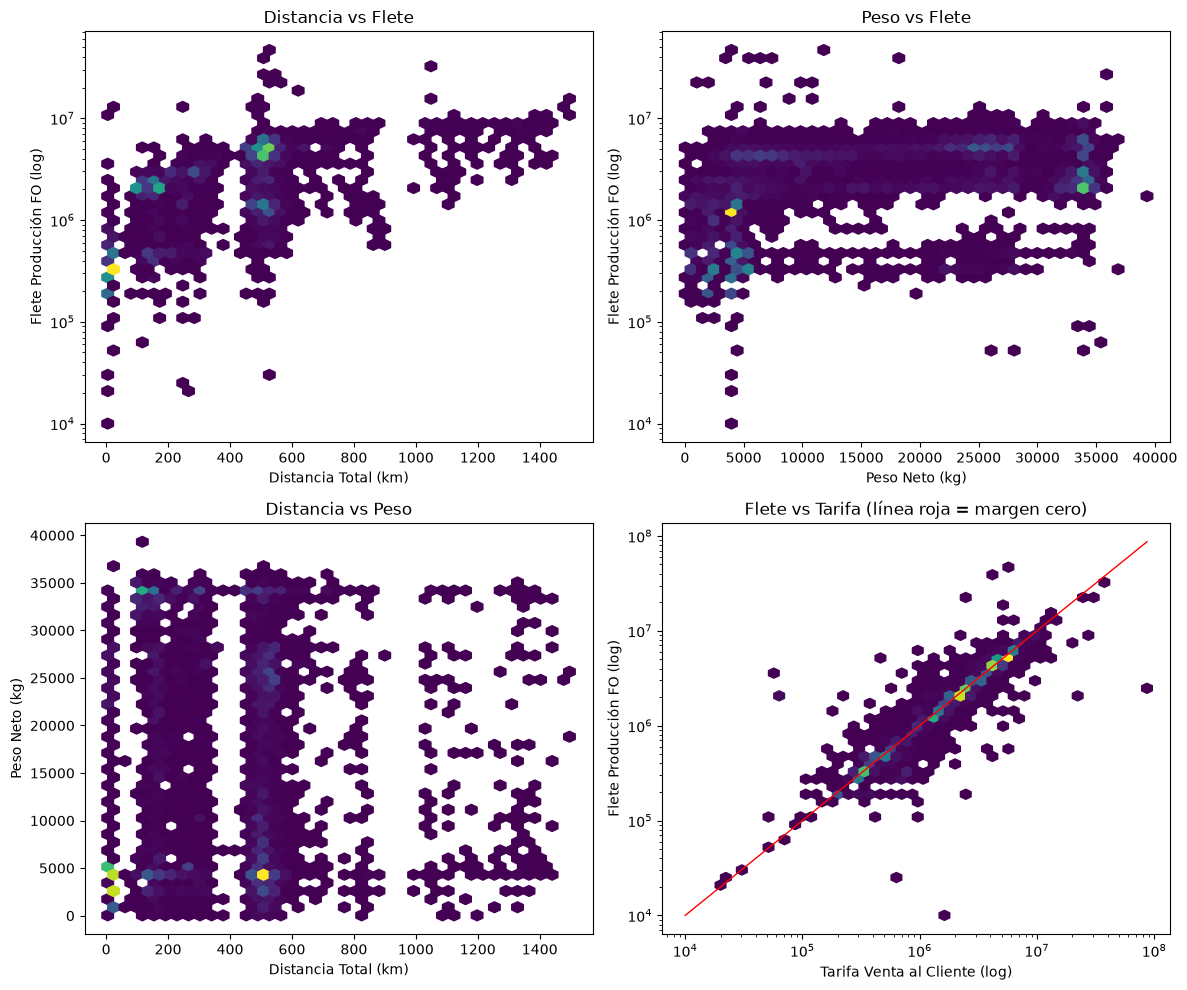

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].hexbin(df_valido["distanciaTotal"], df_valido["fleteProduccionFo"],
                   gridsize=40, yscale="log", cmap="viridis", mincnt=1)
axes[0, 0].set_xlabel("Distancia Total (km)")
axes[0, 0].set_ylabel("Flete Producción FO (log)")
axes[0, 0].set_title("Distancia vs Flete")

axes[0, 1].hexbin(df_valido["pesoNeto"], df_valido["fleteProduccionFo"],
                   gridsize=40, yscale="log", cmap="viridis", mincnt=1)
axes[0, 1].set_xlabel("Peso Neto (kg)")
axes[0, 1].set_ylabel("Flete Producción FO (log)")
axes[0, 1].set_title("Peso vs Flete")

axes[1, 0].hexbin(df_valido["distanciaTotal"], df_valido["pesoNeto"],
                   gridsize=40, cmap="viridis", mincnt=1)
axes[1, 0].set_xlabel("Distancia Total (km)")
axes[1, 0].set_ylabel("Peso Neto (kg)")
axes[1, 0].set_title("Distancia vs Peso")

axes[1, 1].hexbin(df_valido["tarifaVentaAlCliente"], df_valido["fleteProduccionFo"],
                   gridsize=40, xscale="log", yscale="log", cmap="viridis", mincnt=1)
lim_min = df_valido[["tarifaVentaAlCliente", "fleteProduccionFo"]].min().min()
lim_max = df_valido[["tarifaVentaAlCliente", "fleteProduccionFo"]].max().max()
axes[1, 1].plot([lim_min, lim_max], [lim_min, lim_max], color="red", linewidth=1)
axes[1, 1].set_xlabel("Tarifa Venta al Cliente (log)")
axes[1, 1].set_ylabel("Flete Producción FO (log)")
axes[1, 1].set_title("Flete vs Tarifa (línea roja = margen cero)")

plt.tight_layout()
plt.savefig("../reportes/figures/04_scatter_numericas.png", dpi=100)
plt.show()


## Síntesis del Paso 3 — Relaciones visuales (hexbin)

**Bandas de distancia:** los puntos no se reparten continuo en el eje de
distancia — se agrupan en columnas fijas (~0-10 km, ~100-150 km, ~500-550
km, y un tramo disperso 600-1.500 km). Confirma en imagen la sospecha del
plan (§7.1): la operación se mueve entre un conjunto acotado de rutas
fijas, la distancia se comporta casi como categoría, no como continuo.

**Dentro de cada banda, el flete varía en más de un orden de magnitud**
(de $10 mil a $10 millones en la misma columna de distancia) — confirma
visualmente el ~48% de varianza explicada calculado en el Paso 2:
distancia sola no alcanza para predecir flete, hace falta más
información.

**Distancia vs Peso:** sin ningún patrón visible — para cada columna de
distancia el peso cubre casi todo el rango (0-38.000 kg). Confirma la
independencia casi total ya vista en la correlación (0,09-0,15).

**Flete vs Tarifa:** los puntos se pegan a la línea de margen cero en
**todo** el rango de precios (de $10 mil a $100 millones), no solo en un
segmento — consistente con la explicación de negocio (olvido de
actualizar precio de venta) como un despiste disperso, no un patrón
sistemático ligado al nivel de precio.

**Hallazgo a tener en cuenta para el futuro modelo:** la columna muy
densa cerca de 0-10 km coincide con el segmento ya identificado de
descontenerización (`Origen = Destino`, 8.966 registros, notebook `02`).
Antes de entrenar cualquier modelo de flete contra distancia, este
segmento debería tratarse aparte — mezclarlo distorsiona la relación
porque tiene distancia≈0 pero flete normal.


## Paso 4 — Flete según categorías

Miramos si el flete cambia según: quién es dueño del vehículo
(`propiedad`), qué tipo de vehículo es (`idMedioTransporteFo` — no
`Tipo`, ya descartado en notebook `03`), qué línea de negocio es
(`idClaseDocumentoFwo`), y en qué posición del viaje (`posicionPrincipalFwop`).

Usamos mediana en vez de promedio (colas largas, §7.2 del plan) y escala
logarítmica en el eje del flete.


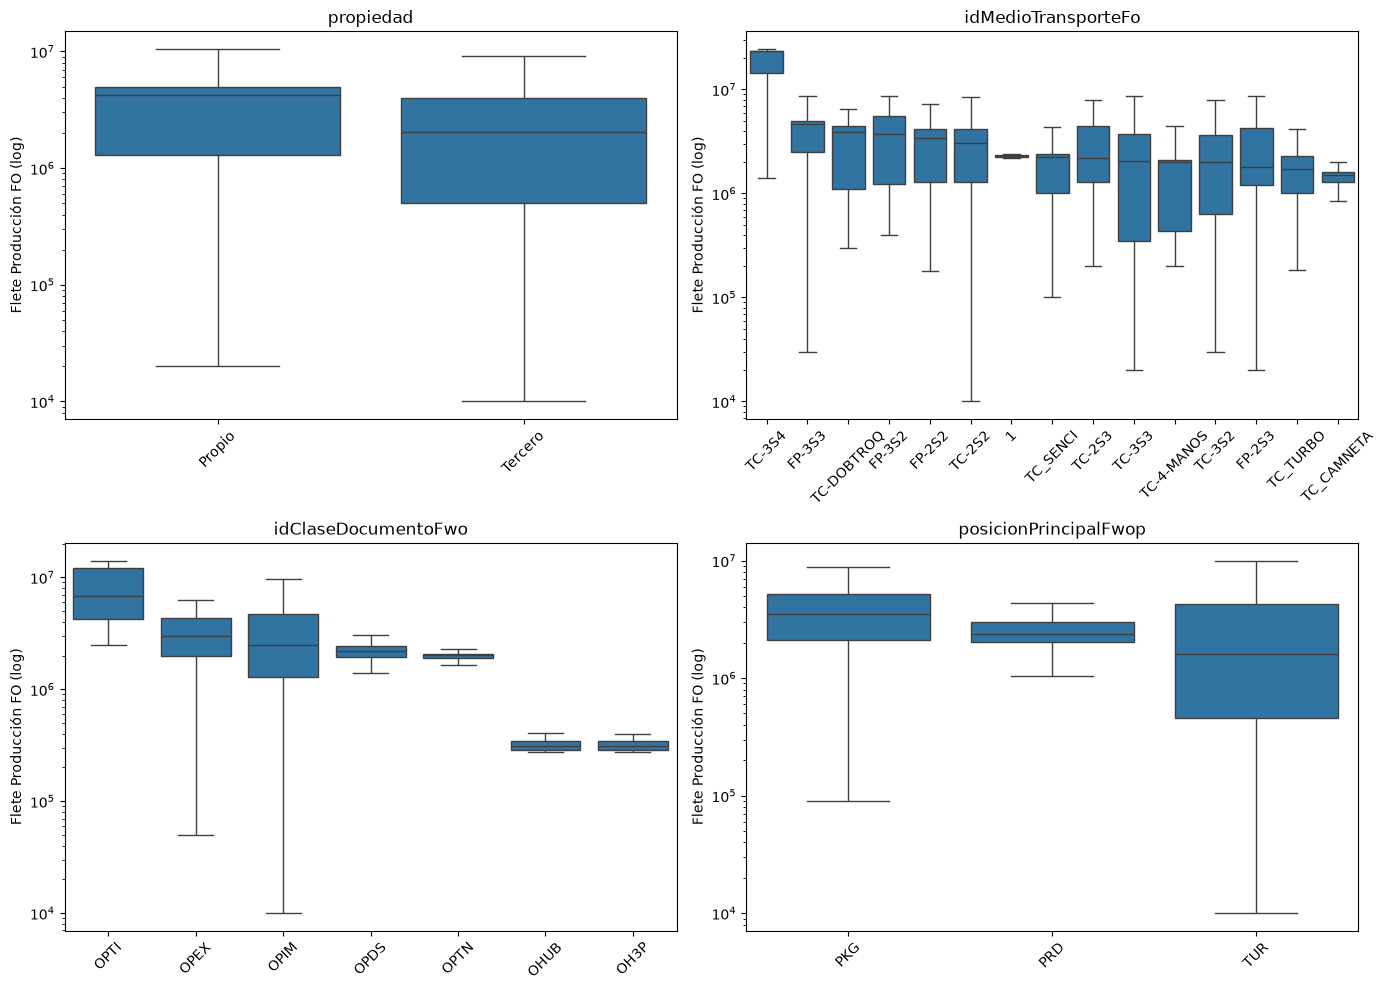

In [24]:
import seaborn as sns

columnas_categoricas_bivariado = ["propiedad", "idMedioTransporteFo", "idClaseDocumentoFwo", "posicionPrincipalFwop"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, col in zip(axes.flat, columnas_categoricas_bivariado):
    orden = df_valido.groupby(col)["fleteProduccionFo"].median().sort_values(ascending=False).index
    sns.boxplot(data=df_valido, x=col, y="fleteProduccionFo", order=orden, ax=ax, showfliers=False)
    ax.set_yscale("log")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Flete Producción FO (log)")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("../reportes/figures/04_boxplots_flete_por_categoria.png", dpi=100)
plt.show()


In [25]:
for col in columnas_categoricas_bivariado:
    print(f"\n--- Mediana y rango intercuartílico de Flete Producción FO por {col} ---")
    resumen = df_valido.groupby(col)["fleteProduccionFo"].agg(
        mediana="median",
        p25=lambda s: s.quantile(0.25),
        p75=lambda s: s.quantile(0.75),
        n="count",
    ).sort_values("mediana", ascending=False)
    print(resumen.round(0))



--- Mediana y rango intercuartílico de Flete Producción FO por propiedad ---
             mediana        p25        p75      n
propiedad                                        
Propio     4200000.0  1300000.0  5000000.0   3550
Tercero    2023200.0   500000.0  4000000.0  36545

--- Mediana y rango intercuartílico de Flete Producción FO por idMedioTransporteFo ---
                        mediana         p25         p75      n
idMedioTransporteFo                                           
TC-3S4               23500000.0  14500000.0  23500000.0      5
FP-3S3                4647000.0   2500000.0   5000000.0   2195
TC-DOBTROQ            3900000.0   1100000.0   4450000.0     67
FP-3S2                3760101.0   1244250.0   5500000.0     28
FP-2S2                3400000.0   1300000.0   4200000.0    905
TC-2S2                3034084.0   1300000.0   4200000.0   7580
1                     2300000.0   2250000.0   2350000.0      2
TC_SENCI              2225000.0   1000000.0   2400000.0    924
TC-2

## Síntesis del Paso 4 — Flete según categorías

**`propiedad`:** Propio paga ~2x más que Tercero en mediana ($4,2M vs
$2,02M, ambos con volumen confiable). El desbalance de volumen (91%
Tercero) se explica por capacidad: la flota propia es de solo ~127
camiones con tope diario de viajes; la diferencia de *precio* no tiene
explicación confirmada todavía.

**`idMedioTransporteFo`:** el orden "camión más grande = paga más" que
sugería el gráfico no se sostiene limpio al revisar los `n` — los
extremos (`TC-3S4` $23,5M, el valor basura `"1"`) tienen muestras
demasiado chicas para ser un patrón real. Entre las 3 categorías con
volumen real, `TC-2S2` paga más que `TC-3S3`/`TC-3S2` pese a sonar "más
chico" por nombre — pendiente de explorar en la Fase 6 multivariado
(§7.5), probablemente cruzando con distancia.

**`idClaseDocumentoFwo`:** confirmado con fuerza — `OHUB`/`OH3P`
(descontenerización) tienen mediana ~$310 mil, un orden de magnitud por
debajo de las demás clases ($2M-$6,75M), con volumen de sobra (7.622
registros) para confiar en el número. Refuerza que la descontenerización
necesita tratarse como segmento aparte en cualquier modelo de flete.

**`posicionPrincipalFwop`:** `TUR` (82% del dato) tiene la mediana más
baja pero el rango más ancho — mezcla los viajes baratos de
descontenerización con los caros de largo recorrido. `PKG`/`PRD` son
nichos más chicos y parejos.

## Paso 5 — Categórica ↔ categórica

Cruzamos categorías entre sí (§7.3 del plan). De los 6 cruces sugeridos,
2 ya se resolvieron en el notebook `02`. De los 4 restantes, cambiamos uno:
en vez de `Posición Principal FWOP × Clase Equipo FOP` (trivial, porque
Clase Equipo FOP solo existe para TUR), usamos `Grupo de Equipo FWOP ×
Clase Equipo FOP` para obtener el mapa real de la jerarquía.


In [26]:
tabla_clase_propiedad = pd.crosstab(df["idClaseDocumentoFwo"], df["propiedad"], normalize="index") * 100
print("% Propio vs Tercero dentro de cada línea de negocio:")
print(tabla_clase_propiedad.round(1).sort_values("Propio", ascending=False))


% Propio vs Tercero dentro de cada línea de negocio:
propiedad            Propio  Tercero
idClaseDocumentoFwo                 
OPIM                   12.0     88.0
OPEX                    4.0     96.0
OH3P                    3.0     97.0
OHUB                    1.2     98.8
OPTN                    0.5     99.5
OPDS                    0.0    100.0
OPTI                    0.0    100.0


In [27]:
tabla_propiedad_medio = pd.crosstab(df["propiedad"], df["idMedioTransporteFo"], normalize="index") * 100
print("% de cada tipo de vehículo, dentro de Propio y dentro de Tercero:")
print(tabla_propiedad_medio.round(1).T.sort_values("Propio", ascending=False))


% de cada tipo de vehículo, dentro de Propio y dentro de Tercero:
propiedad            Propio  Tercero
idMedioTransporteFo                 
FP-3S3                 61.3      0.0
FP-2S2                 24.8      0.1
FP-2S3                  7.8      0.0
TC-2S2                  3.2     20.8
TC-3S3                  1.3     59.3
FP-3S2                  0.8      0.0
TC-2S3                  0.6      3.4
TC-3S2                  0.2      8.3
1                       0.0      0.0
TC-3S4                  0.0      0.0
TC-4-MANOS              0.0      0.6
TC-DOBTROQ              0.0      0.2
TC_CAMNETA              0.0      1.6
TC_SENCI                0.0      2.5
TC_TURBO                0.0      3.2


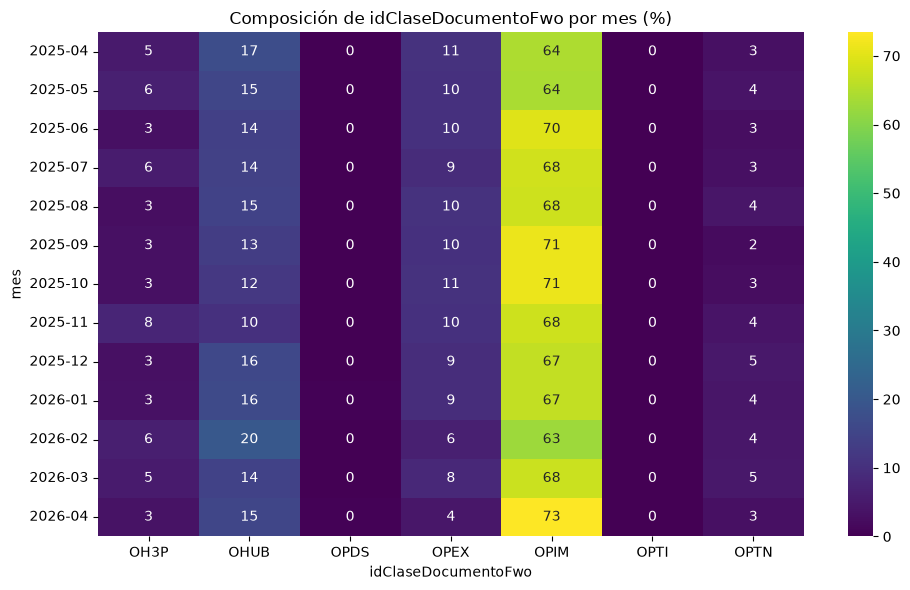

In [28]:
df["mes"] = df["fechaCreacionFo"].dt.to_period("M").astype(str)
tabla_clase_mes = pd.crosstab(df["mes"], df["idClaseDocumentoFwo"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(tabla_clase_mes, annot=True, fmt=".0f", cmap="viridis", ax=ax)
ax.set_title("Composición de idClaseDocumentoFwo por mes (%)")
plt.tight_layout()
plt.savefig("../reportes/figures/04_heatmap_clase_por_mes.png", dpi=100)
plt.show()


In [29]:
tabla_grupo_clase = pd.crosstab(df["grupoDeEquipoFwop"], df["claseEquipoFop"])
tabla_grupo_clase = tabla_grupo_clase.loc[:, (tabla_grupo_clase > 0).any()]
print("Qué clases de equipo pertenecen a cada grupo (CN/CAM):")
print(tabla_grupo_clase.T)


Qué clases de equipo pertenecen a cada grupo (CN/CAM):
grupoDeEquipoFwop   CAM     CN
claseEquipoFop                
2S2.18T             201      0
2S3.MM25T            57      0
3S2.32T             276      0
3S3.34T            3323      0
C2.2T                 1      0
C2.4.5T            1062      0
C2.8T               459      0
C3.DT.17T             4      0
CNT20.FT              0      2
CNT20.HC              0    388
CNT20.IT              0     34
CNT20.OT              0      6
CNT20.PF              0      1
CNT20.RE              0      1
CNT20.ST              0   7308
CNT20.STCO            0      2
CNT40.FT              0     41
CNT40.HC              1  19425
CNT40.HCCO            0      3
CNT40.IT              0      2
CNT40.OT              0     20
CNT40.RE              0    586
CNT40.RHC             0      7
CNT40.ST              0    519
CNT45.ST              0      5
P3S2.T32T             3      0
P3S3.T34T             1      0


## Síntesis del Paso 5 — Categórica ↔ categórica

**Propiedad × línea de negocio:** Propio se concentra en `OPIM` (12% del
volumen de esa línea) y casi no toca la descontenerización (`OHUB` 1,2%,
`OH3P` 3%) — coherente con reservar la flota propia (127 camiones, tope
diario) para el negocio principal.

**Propiedad × tipo de vehículo — el hallazgo más fuerte:** separación casi
total entre flotas. Propio usa casi exclusivamente vehículos `FP-*`
(94,7% del total Propio); Tercero usa casi exclusivamente `TC-*`
(~100%). Probable convención de nomenclatura (`FP` = Flota Propia).
**Esto reabre la pregunta del Paso 4:** la brecha de precio entre Propio
y Tercero puede deberse más a que usan flotas de vehículo totalmente
distintas (con su propia estructura de tarifa) que a la propiedad en sí
— no se puede separar un efecto del otro con este cruce solo.

**Línea de negocio × mes:** mezcla de negocio estable en toda la ventana,
`OPIM` domina siempre (63-73%). Única señal a vigilar: `OPEX` muestra
tendencia a la baja en los últimos 3 meses (9-11% → 4-8%) — no
confirmado, podría ser tendencia real o ruido de la muestra. Abril 2026
(mes parcial, ~523 registros) se lee con cautela.

**Grupo × clase de equipo — mapa confirmado:** separación limpia por
prefijo (numérico → `CAM`, `CNT` → `CN`), con **1 sola fila mal
clasificada** (`CNT40.HC` en `CAM`) — defecto real pero mínimo. Explica
por qué `claseEquipoFop` mostraba solo asociación media con las columnas
de vehículo en el notebook `03`: mezcla clases de camión (si se parecen)
con clases de contenedor (que no tienen relación con el vehículo).


## Paso 6 — Variable de margen (exploratorio, §7.4 del plan)

**Advertencia (igual que el plan §7.4):** esto es exploratorio, no una
cifra de rentabilidad para reportar — la semántica exacta de las columnas
monetarias no está 100% confirmada (§1.2). Además, el modelo futuro
apunta a predecir el flete, no el margen — esta sección queda como
contexto, no como foco del EDA.

Reutilizamos `df_valido` (tarifa y flete ya filtrados > 0), por lo que no
hace falta manejar división por cero aparte.


In [30]:
df_valido["margen"] = df_valido["tarifaVentaAlCliente"] - df_valido["fleteProduccionFo"]
df_valido["margenPct"] = df_valido["margen"] / df_valido["tarifaVentaAlCliente"]

pct_negativo = (df_valido["margen"] < 0).mean() * 100
print(f"% de viajes con margen negativo: {pct_negativo:.2f}%")
print(f"Mediana margen: ${df_valido['margen'].median():,.0f}")
print(f"Mediana margen %: {df_valido['margenPct'].median()*100:.1f}%")

print("\nMediana de margen % por propiedad:")
print((df_valido.groupby("propiedad")["margenPct"].median() * 100).round(1))

print("\nMediana de margen % por línea de negocio:")
print((df_valido.groupby("idClaseDocumentoFwo")["margenPct"].median().sort_values(ascending=False) * 100).round(1))


% de viajes con margen negativo: 7.40%
Mediana margen: $0
Mediana margen %: 0.0%

Mediana de margen % por propiedad:
propiedad
Propio     0.0
Tercero    0.0
Name: margenPct, dtype: float64

Mediana de margen % por línea de negocio:
idClaseDocumentoFwo
OH3P    0.0
OHUB    0.0
OPDS    0.0
OPEX    0.0
OPIM    0.0
OPTI    0.0
OPTN    0.0
Name: margenPct, dtype: float64


In [31]:
pct_exacto = (df_valido["tarifaVentaAlCliente"] == df_valido["fleteProduccionFo"]).mean() * 100
print(f"% de filas donde Tarifa == Flete exactamente: {pct_exacto:.2f}%")


% de filas donde Tarifa == Flete exactamente: 72.22%


## Síntesis del Paso 6 — Variable de margen

**Hallazgo principal, más grande de lo esperado:** en el 72,22% de las
filas válidas, `Tarifa Venta al Cliente` es **exactamente igual** a
`Flete Producción FO` — no una coincidencia posible al azar con columnas
de miles de valores distintos. Por eso la mediana de margen dio $0 en
absolutamente todas las categorías (propiedad, línea de negocio):
el "empate" está en todos lados, no concentrado en un segmento.

**Causa (confirmada con el negocio):** `Tarifa Venta al Cliente` está
mal capturada desde los sistemas de origen en este extracto específico
— posiblemente sí se registra bien en otra tabla de la compañía, pero no
en `Viajes-Btura-2025-2026.xlsx`.

**Conclusión — esta columna no es confiable en este set.** Cualquier
análisis de margen/rentabilidad calculado sobre este extracto queda
descartado, no solo "exploratorio" como advertía el plan originalmente
— el problema es más profundo que la semántica de nombres (§1.2): es
un defecto de captura. Esto refuerza la decisión de enfocar el EDA y el
futuro modelo en `Flete Producción FO`, que no muestra este problema y
sí se relacionó de forma sensata con distancia, peso y tipo de vehículo
en los Pasos 2-5.

**Para el informe de hallazgos (§13 del plan):** este es un hallazgo de
severidad alta a documentar aparte, con recomendación de usar la tabla
correcta de origen para `Tarifa Venta al Cliente` si en el futuro se
necesita analizar rentabilidad.


## Paso 7 — Multivariado: cerrando el pendiente de TC-2S2

Antes de pasar a segmentación general (§7.5 del plan), resolvemos la
pregunta abierta del Paso 4: ¿`TC-2S2` paga más que `TC-3S3`/`TC-3S2`
porque hace rutas distintas (más distancia o más peso)? Cruzamos las 3
variables a la vez para las 3 categorías de vehículo con volumen
confiable.


In [32]:
categorias_grandes = ["TC-3S3", "TC-2S2", "TC-3S2"]
resumen_tc = df_valido[df_valido["idMedioTransporteFo"].isin(categorias_grandes)].groupby("idMedioTransporteFo").agg(
    n=("fleteProduccionFo", "count"),
    flete_mediana=("fleteProduccionFo", "median"),
    distancia_mediana=("distanciaTotal", "median"),
    peso_mediana=("pesoNeto", "median"),
).round(0)

print(resumen_tc.sort_values("flete_mediana", ascending=False))


                         n  flete_mediana  distancia_mediana  peso_mediana
idMedioTransporteFo                                                       
TC-2S2                7580      3034084.0              501.0        4886.0
TC-3S3               21795      2038400.0              156.0       23500.0
TC-3S2                3042      2000000.0              156.0       20716.0


## Paso 7 (continuación) — Segmentación de rutas (clustering exploratorio)

Agrupamos rutas (origen→destino) por 3 características a la vez: volumen
de viajes, distancia mediana y flete mediano (§7.5 del plan, adaptado a
flete en vez de margen). Usamos K-Means, con las variables escaladas
(mismas unidades relativas) para que ninguna domine solo por tener
números más grandes. Exploratorio, no un modelo entregable — sin
afinar el número de grupos con rigor.


In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

rutas = df_valido.groupby(["origen", "destino"]).agg(
    n_viajes=("fleteProduccionFo", "count"),
    distancia_mediana=("distanciaTotal", "median"),
    flete_mediano=("fleteProduccionFo", "median"),
).reset_index()

rutas_frecuentes = rutas[rutas["n_viajes"] >= 20].copy()
print(f"Rutas con al menos 20 viajes: {rutas_frecuentes.shape[0]} de {rutas.shape[0]} rutas totales")

X = rutas_frecuentes[["n_viajes", "distancia_mediana", "flete_mediano"]]
X_escalado = StandardScaler().fit_transform(X)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rutas_frecuentes["cluster"] = kmeans.fit_predict(X_escalado)

print("\nCaracterísticas medianas de cada cluster:")
print(rutas_frecuentes.groupby("cluster")[["n_viajes", "distancia_mediana", "flete_mediano"]].median().round(0))
print("\nCantidad de rutas por cluster:")
print(rutas_frecuentes["cluster"].value_counts().sort_index())


Rutas con al menos 20 viajes: 102 de 226 rutas totales

Características medianas de cada cluster:
         n_viajes  distancia_mediana  flete_mediano
cluster                                            
0           127.0              515.0      4729400.0
1           180.0              240.0      1500000.0
2          8495.0               10.0       310000.0
3            52.0             1080.0      8000000.0

Cantidad de rutas por cluster:
cluster
0    39
1    54
2     1
3     8
Name: count, dtype: int64


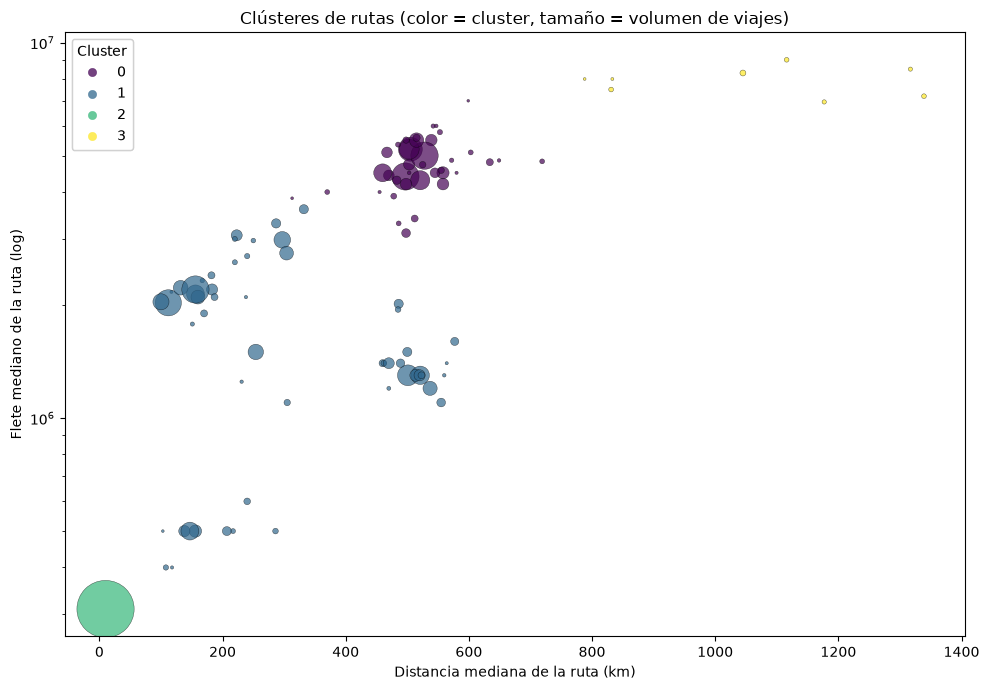

In [34]:
fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(rutas_frecuentes["distancia_mediana"], rutas_frecuentes["flete_mediano"],
                      c=rutas_frecuentes["cluster"], s=rutas_frecuentes["n_viajes"] / 5,
                      cmap="viridis", alpha=0.7, edgecolors="black", linewidth=0.3)
ax.set_yscale("log")
ax.set_xlabel("Distancia mediana de la ruta (km)")
ax.set_ylabel("Flete mediano de la ruta (log)")
ax.set_title("Clústeres de rutas (color = cluster, tamaño = volumen de viajes)")
legend1 = ax.legend(*scatter.legend_elements(), title="Cluster")
ax.add_artist(legend1)
plt.tight_layout()
plt.savefig("../reportes/figures/04_clusters_rutas.png", dpi=100)
plt.show()


## Síntesis del notebook 04 — Análisis bivariado y multivariado

**Objetivo cumplido (Fase 6, §7 del plan):** encontrar relaciones entre
columnas, con foco en `Flete Producción FO` como variable objetivo del
futuro modelo predictivo (no margen ni tarifa, aclarado por el negocio).

**Numérica ↔ numérica (Pasos 2-3):** distancia y peso son casi
independientes entre sí (Spearman 0,15) — buena señal, no son
redundantes como predictores. Cada una explica solo una parte del flete
(distancia ~48% de la varianza en términos de Pearson, peso algo menos):
hace falta más información para predecirlo bien. Los gráficos confirmaron
que la distancia se comporta casi como categoría (rutas fijas en bandas),
no como continuo, y delataron una columna densa cerca de 0-10 km — el
segmento de descontenerización, que aparece una y otra vez en todo el
notebook.

**Categórica ↔ numérica (Paso 4):** `idMedioTransporteFo` (no `Tipo`,
descartado en el `03`) sí varía con el flete, aunque no por tamaño de
camión de forma simple. `idClaseDocumentoFwo` mostró la diferencia más
fuerte: descontenerización (`OHUB`/`OH3P`) cuesta un orden de magnitud
menos que el resto ($310 mil vs $2M-$6,75M).

**Categórica ↔ categórica (Paso 5):** flota propia concentrada en el
negocio principal (`OPIM`) y casi ausente de la descontenerización.
Hallazgo fuerte: `idMedioTransporteFo` y `propiedad` casi se determinan
mutuamente (prefijo `FP-` = Propio, `TC-` = Tercero casi sin excepción)
— la brecha de precio Propio/Tercero puede deberse más a qué flota de
vehículos usa cada uno que a la propiedad en sí. Mezcla de negocio
estable en el tiempo. Jerarquía `grupoDeEquipoFwop`↔`claseEquipoFop`
confirmada con mapa concreto (1 sola fila mal clasificada).

**Margen (Paso 6) — hallazgo mayor, no esperado:** en 72,2% de las filas
válidas, `Tarifa Venta al Cliente` es idéntica a `Flete Producción FO`.
Confirmado con el negocio: esa columna está mal capturada en este
extracto específico. **`Tarifa Venta al Cliente` queda descartada como
no confiable en este set** — refuerza enfocar el EDA y el modelo en
`Flete Producción FO`.

**Multivariado (Paso 7):** el caso `TC-2S2` (pagaba más que camiones
"más grandes") se explicó al cruzar 3 variables a la vez: hace rutas
3,2x más largas con 4-5x menos peso — el tipo de vehículo funciona como
un perfil de ruta, no solo como tamaño físico. El clustering de rutas
(K-Means, exploratorio) redescubrió por su cuenta el segmento de
descontenerización como una ruta única y extrema (8.495 viajes, 10 km,
$310 mil), y ordenó el resto en una escalera de distancia-precio-volumen
coherente con todo lo anterior.

**Qué le queda listo a los notebooks/pasos siguientes:**
- `05_temporal_y_geografico.ipynb`: profundizar estacionalidad completa
  (Paso 6 solo tocó día de semana) y tratar el segmento de
  descontenerización aparte en cualquier análisis geográfico — ya
  sabemos que es prácticamente una sola "ruta" con volumen masivo.
- `06_outliers_y_sesgos.ipynb`: revisar puntualmente las categorías de
  muestra minúscula detectadas acá (`TC-3S4` n=5, `OPTI` n=22, valor
  basura `"1"` n=2, la fila `CNT40.HC` mal clasificada).
- **Futuro modelo predictivo:** variables con señal confirmada para
  predecir flete — `distanciaTotal`, `pesoNeto`, `idMedioTransporteFo`,
  `idClaseDocumentoFwo` (clave para separar descontenerización del resto).
  `propiedad` aporta poco adicional una vez que se tiene
  `idMedioTransporteFo` (casi redundantes). `tarifaVentaAlCliente`
  queda fuera del modelo por no ser confiable en este set.
